# NB23 — Confidence Intervals vs Prediction Intervals

> **StatQuest principle: "Where is the average?" and "Where will the next point land?" are two different questions — and the second one always has a wider answer.**

---

## The main ideas are:

1. A **confidence interval (CI)** brackets the **mean** response $E[y\mid x_0]$ — uncertainty in the fitted line only
2. A **prediction interval (PI)** brackets a **new single observation** $y_0$ — line uncertainty **plus** the noise $\sigma^2$
3. Formulas (simple regression):
   $se_{fit}(x_0) = \hat\sigma\sqrt{\frac{1}{n} + \frac{(x_0-\bar x)^2}{S_{xx}}}$,
   $\;\; se_{pred}(x_0) = \hat\sigma\sqrt{1 + \frac{1}{n} + \frac{(x_0-\bar x)^2}{S_{xx}}}$
4. Both are narrowest at $\bar x$ and **widen** as $x_0$ moves away
5. As n grows, the CI shrinks to zero width; the PI never shrinks below $\approx \pm 1.96\sigma$
6. Far outside the data (extrapolation), both formulas assume the line stays straight — they can be badly wrong


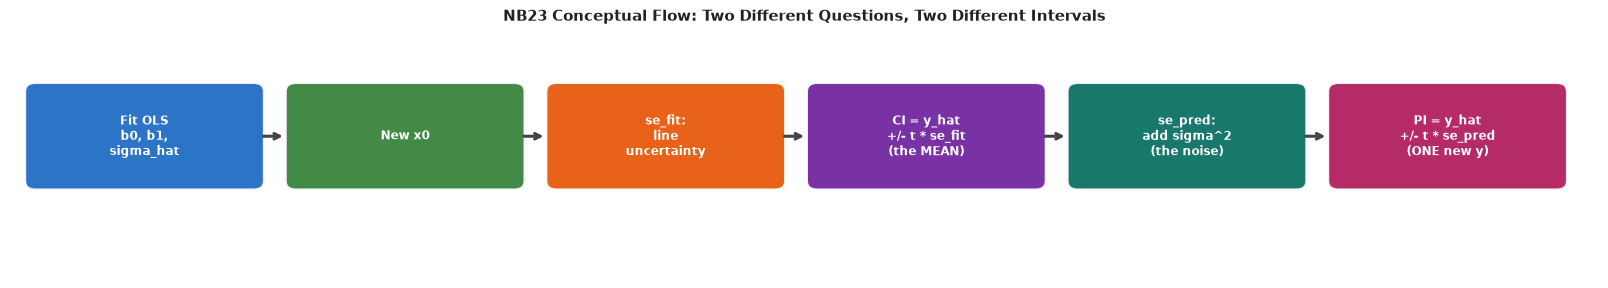

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

def flow_diagram(steps, title, colors=None, notes=None, figsize=(14, 2.8)):
    """Draw a horizontal flow diagram.  steps = list of strings."""
    n = len(steps)
    default_colors = [
        '#1565C0','#2E7D32','#E65100','#6A1B9A',
        '#00695C','#AD1457','#37474F','#4E342E',
        '#0277BD','#558B2F',
    ]
    colors = (colors or default_colors[:n]) + default_colors
    notes  = notes or [''] * n

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-0.3, n * 3.1)
    ax.set_ylim(-1.2, 2.4)
    ax.axis('off')

    bw, bh = 2.6, 1.3
    for i, (step, color, note) in enumerate(zip(steps, colors, notes)):
        x = i * 3.1
        box = FancyBboxPatch((x, 0.2), bw, bh,
                             boxstyle="round,pad=0.12",
                             facecolor=color, edgecolor='white', linewidth=1.5, alpha=0.90)
        ax.add_patch(box)
        ax.text(x + bw/2, 0.2 + bh/2, step,
                ha='center', va='center', fontsize=8.5,
                color='white', fontweight='bold', multialignment='center')
        if note:
            ax.text(x + bw/2, 0.02, note,
                    ha='center', va='top', fontsize=7, color='#555', style='italic')
        if i < n - 1:
            ax.annotate('',
                xy=(x + bw + 0.38, 0.2 + bh/2),
                xytext=(x + bw + 0.08, 0.2 + bh/2),
                arrowprops=dict(arrowstyle='->', color='#444', lw=2.2))

    ax.set_title(title, fontsize=11, fontweight='bold', pad=6, color='#222')
    plt.tight_layout(pad=0.4)
    plt.show()

flow_diagram(
    steps=[
        'Fit OLS\nb0, b1,\nsigma_hat',
        'New x0',
        'se_fit:\nline\nuncertainty',
        'CI = y_hat\n+/- t * se_fit\n(the MEAN)',
        'se_pred:\nadd sigma^2\n(the noise)',
        'PI = y_hat\n+/- t * se_pred\n(ONE new y)',
    ],
    title='NB23 Conceptual Flow: Two Different Questions, Two Different Intervals',
    figsize=(16, 2.8),
)


## Step 1 — Data and fit

Synthetic: n = 30, x ~ U(0, 10), y = 5 + 2x + N(0, 3²), seed 23.


In [2]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(23)
n = 30
x = np.sort(rng.uniform(0, 10, n))
y = 5 + 2 * x + rng.normal(0, 3, n)
res = sm.OLS(y, sm.add_constant(x)).fit()
b0, b1 = res.params
sigma = np.sqrt(res.scale)
print(f"Fit: y_hat = {b0:.3f} + {b1:.3f} x     sigma_hat = {sigma:.3f}  (true sigma = 3)")
print(f"x_bar = {x.mean():.3f}, n = {n}, df = {n-2}")


Fit: y_hat = 6.423 + 1.678 x     sigma_hat = 3.724  (true sigma = 3)
x_bar = 4.915, n = 30, df = 28


## Step 2 — Compute both intervals by hand, then with statsmodels

`get_prediction(...).summary_frame(alpha=0.05)` returns:
- `mean_ci_lower / mean_ci_upper` → the **CI** for the mean
- `obs_ci_lower / obs_ci_upper` → the **PI** for a new observation


In [3]:
import numpy as np
import pandas as pd
from scipy import stats

Sxx = np.sum((x - x.mean()) ** 2)
tcrit = stats.t.ppf(0.975, n - 2)
x0s = np.array([x.mean(), 2.0, 9.0, 15.0])

rows = []
for x0 in x0s:
    yhat = b0 + b1 * x0
    se_fit = sigma * np.sqrt(1 / n + (x0 - x.mean()) ** 2 / Sxx)
    se_pred = sigma * np.sqrt(1 + 1 / n + (x0 - x.mean()) ** 2 / Sxx)
    rows.append([x0, yhat, se_fit, yhat - tcrit * se_fit, yhat + tcrit * se_fit,
                 se_pred, yhat - tcrit * se_pred, yhat + tcrit * se_pred])
by_hand = pd.DataFrame(rows, columns=['x0', 'y_hat', 'se_fit', 'CI_low', 'CI_high',
                                      'se_pred', 'PI_low', 'PI_high']).round(3)
print(f"t critical (95%, df={n-2}) = {tcrit:.4f}\n")
print("By hand:")
print(by_hand.to_string(index=False))

sf = res.get_prediction(np.column_stack([np.ones(len(x0s)), x0s])).summary_frame(alpha=0.05)
print("\nstatsmodels summary_frame:")
print(sf.round(3).to_string())
print("\nMatch:", bool(np.allclose(sf['mean_ci_lower'], by_hand['CI_low'], atol=1e-3)
                    and np.allclose(sf['obs_ci_upper'], by_hand['PI_high'], atol=1e-3)))
w = by_hand.iloc[0]
print(f"\nAt x_bar: CI width = {w.CI_high - w.CI_low:.2f}, PI width = {w.PI_high - w.PI_low:.2f}  "
      f"({(w.PI_high - w.PI_low)/(w.CI_high - w.CI_low):.1f}x wider)")


t critical (95%, df=28) = 2.0484

By hand:
    x0  y_hat  se_fit  CI_low  CI_high  se_pred  PI_low  PI_high
 4.915 14.668   0.680  13.276   16.061    3.786   6.913   22.424
 2.000  9.778   1.004   7.721   11.836    3.858   1.877   17.680
 9.000 21.522   1.239  18.983   24.060    3.925  13.481   29.562
15.000 31.587   2.647  26.166   37.009    4.569  22.228   40.947

statsmodels summary_frame:
     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  14.668    0.680         13.276         16.061         6.913        22.424
1   9.778    1.004          7.721         11.836         1.877        17.680
2  21.522    1.239         18.983         24.060        13.481        29.562
3  31.587    2.647         26.166         37.009        22.228        40.947

Match: True

At x_bar: CI width = 2.79, PI width = 15.51  (5.6x wider)


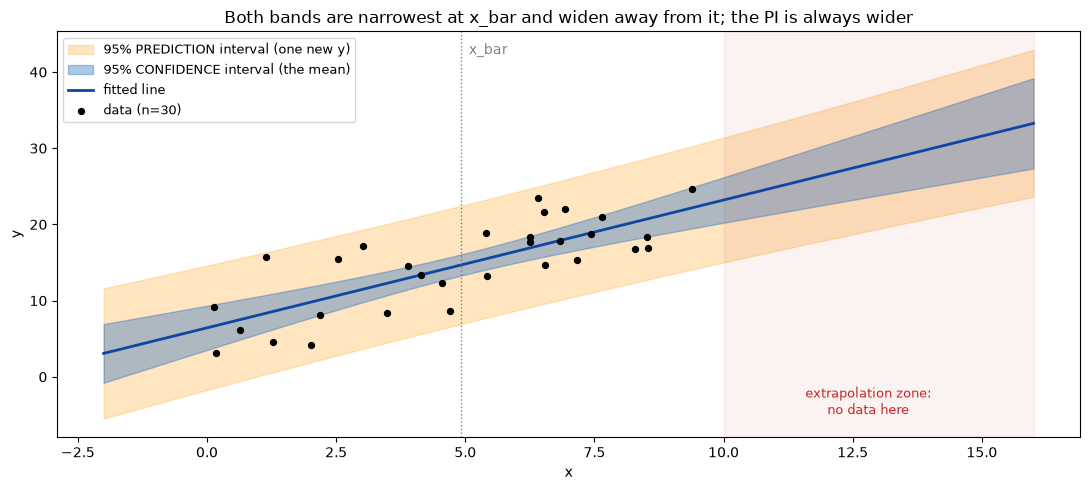

In [4]:
import numpy as np
import matplotlib.pyplot as plt

grid = np.linspace(-2, 16, 300)
sf_g = res.get_prediction(np.column_stack([np.ones_like(grid), grid])).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(grid, sf_g['obs_ci_lower'], sf_g['obs_ci_upper'], color='#FFB74D', alpha=0.35, label='95% PREDICTION interval (one new y)')
ax.fill_between(grid, sf_g['mean_ci_lower'], sf_g['mean_ci_upper'], color='#1565C0', alpha=0.35, label='95% CONFIDENCE interval (the mean)')
ax.plot(grid, sf_g['mean'], color='#0D47A1', lw=2, label='fitted line')
ax.scatter(x, y, color='k', s=18, zorder=3, label='data (n=30)')
ax.axvspan(10, 16, color='#C62828', alpha=0.06)
ax.text(12.8, ax.get_ylim()[0] + 3, 'extrapolation zone:\nno data here', ha='center', color='#C62828', fontsize=9)
ax.axvline(x.mean(), color='gray', ls=':', lw=1); ax.text(x.mean(), ax.get_ylim()[1] - 3, '  x_bar', color='gray')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Both bands are narrowest at x_bar and widen away from it; the PI is always wider')
ax.legend(loc='upper left', fontsize=9); plt.tight_layout(); plt.show()


## Step 3 — Coverage simulation: does each interval do its job?

Repeat 2,000 times: draw a new dataset from the true model, build both intervals at $x_0 = 9$, and check
- does the **CI** contain the true mean $5 + 2\cdot 9 = 23$?
- does the **PI** contain a **fresh** observation $y_0$?

And the common mistake: using the CI to bracket a new observation.


In [5]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(230)
reps, x0 = 2000, 9.0
true_mean = 5 + 2 * x0
ci_hit = pi_hit = ci_for_new = 0
for _ in range(reps):
    xs = rng.uniform(0, 10, n)
    ys = 5 + 2 * xs + rng.normal(0, 3, n)
    r = sm.OLS(ys, sm.add_constant(xs)).fit()
    f = r.get_prediction(np.array([[1.0, x0]])).summary_frame(alpha=0.05).iloc[0]
    y_new = true_mean + rng.normal(0, 3)
    ci_hit += f.mean_ci_lower <= true_mean <= f.mean_ci_upper
    pi_hit += f.obs_ci_lower <= y_new <= f.obs_ci_upper
    ci_for_new += f.mean_ci_lower <= y_new <= f.mean_ci_upper
print(f"CI contains the true MEAN      : {ci_hit/reps:.1%}   (target 95%)")
print(f"PI contains a NEW observation  : {pi_hit/reps:.1%}   (target 95%)")
print(f"CI misused for a new observation: {ci_for_new/reps:.1%}   <- far below 95%: the classic mistake")


CI contains the true MEAN      : 95.1%   (target 95%)
PI contains a NEW observation  : 95.7%   (target 95%)
CI misused for a new observation: 46.7%   <- far below 95%: the classic mistake


## Step 4 — More data shrinks the CI, but not the PI

$se_{fit} \to 0$ as $n \to \infty$, but $se_{pred} \to \sigma$. Irreducible noise stays.


n=   10:  CI width =   5.85   PI width =  19.38
n=   30:  CI width =   2.18   PI width =  11.51
n=  100:  CI width =   1.13   PI width =  11.08
n=  300:  CI width =   0.66   PI width =  11.51
n= 1000:  CI width =   0.38   PI width =  12.09
n= 3000:  CI width =   0.21   PI width =  11.72

PI width floor = 2 x 1.96 x sigma = 11.76


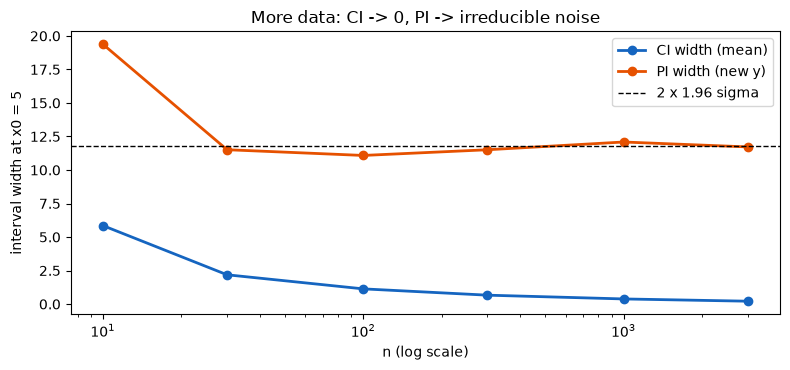

In [6]:
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

rng = np.random.default_rng(231)
ns = [10, 30, 100, 300, 1000, 3000]
ci_w, pi_w = [], []
for m in ns:
    xs = rng.uniform(0, 10, m)
    ys = 5 + 2 * xs + rng.normal(0, 3, m)
    f = sm.OLS(ys, sm.add_constant(xs)).fit().get_prediction(np.array([[1.0, 5.0]])).summary_frame(alpha=0.05).iloc[0]
    ci_w.append(f.mean_ci_upper - f.mean_ci_lower)
    pi_w.append(f.obs_ci_upper - f.obs_ci_lower)
    print(f"n={m:5d}:  CI width = {ci_w[-1]:6.2f}   PI width = {pi_w[-1]:6.2f}")
print(f"\nPI width floor = 2 x 1.96 x sigma = {2*1.96*3:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.semilogx(ns, ci_w, 'o-', color='#1565C0', lw=2, label='CI width (mean)')
ax.semilogx(ns, pi_w, 'o-', color='#E65100', lw=2, label='PI width (new y)')
ax.axhline(2 * 1.96 * 3, color='k', ls='--', lw=1, label='2 x 1.96 sigma')
ax.set_xlabel('n (log scale)'); ax.set_ylabel('interval width at x0 = 5'); ax.legend()
ax.set_title('More data: CI -> 0, PI -> irreducible noise'); plt.tight_layout(); plt.show()


## Step 5 — Extrapolation: the intervals only know about the model you assumed

If the truth curves outside the data range, both intervals (built on the straight-line assumption) miss completely.


In [7]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(232)
xs = rng.uniform(0, 10, 60)
truth = lambda v: 5 + 2 * v + 0.15 * np.maximum(v - 10, 0) ** 2 * 10   # straight on [0,10], bends after 10
ys = truth(xs) + rng.normal(0, 3, 60)
r = sm.OLS(ys, sm.add_constant(xs)).fit()
for x0 in [5, 10, 15, 20]:
    f = r.get_prediction(np.array([[1.0, x0]])).summary_frame(alpha=0.05).iloc[0]
    inside = f.obs_ci_lower <= truth(x0) <= f.obs_ci_upper
    print(f"x0={x0:>2}: PI = [{f.obs_ci_lower:6.1f}, {f.obs_ci_upper:6.1f}]   true mean = {truth(x0):6.1f}   "
          f"{'inside' if inside else 'OUTSIDE  <- extrapolation failure'}")


x0= 5: PI = [   9.6,   20.6]   true mean =   15.0   inside
x0=10: PI = [  21.1,   32.5]   true mean =   25.0   inside
x0=15: PI = [  32.3,   44.8]   true mean =   72.5   OUTSIDE  <- extrapolation failure
x0=20: PI = [  43.2,   57.4]   true mean =  195.0   OUTSIDE  <- extrapolation failure


## Key Takeaways

| Question | Interval | Standard error | Shrinks with more data? |
|---|---|---|---|
| Where is the **average** y at x0? | Confidence interval | $\hat\sigma\sqrt{1/n + (x_0-\bar x)^2/S_{xx}}$ | Yes → 0 |
| Where will **one new** y land? | Prediction interval | $\hat\sigma\sqrt{1 + 1/n + (x_0-\bar x)^2/S_{xx}}$ | No → about ±1.96σ |

- Both are narrowest at $\bar x$ and widen away from it
- statsmodels: `get_prediction(X0).summary_frame()` → `mean_ci_*` (CI) and `obs_ci_*` (PI)
- Using a CI to bracket a new observation badly under-covers
- Outside the data range, both intervals inherit the (untested) assumption that the model still holds
- Both assume homoscedastic, roughly normal errors (NB06); otherwise consider quantile regression (NB17)
